# Task 2.4: improving readout while preserving the memory

**Result.** Resonant modulation increases the buffer signal relative to the recovered loss of memory amplitude. A complementary strategy, temporary cat enlargement, gives a **2.33-fold shorter complete cycle** at equal calculated signal and a readout-stage $\Gamma_X$ below undriven storage. Both results use the full **cubic two-mode Lindblad model**; the circuit calculation below tests its approximation separately.

We follow parts (a)–(d): derive the controls, quantify the drive trade-off, compare protocols, and assess the evidence. [Concise report](../docs/task_2.md). Cells load saved results; no quantum simulation is required.


In [1]:
from pathlib import Path
import sys, io, json
from contextlib import redirect_stdout
from math import factorial, exp, sqrt, pi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import base64

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F, linresp
from research.s2.common import G2, KAPPA_B
from src import plotting as P
def show(name, w=860):
    path = ROOT / "figures" / f"{name}.png"
    data = base64.b64encode(path.read_bytes()).decode()
    display({"image/png": data, "text/html": f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{w}" alt="{name}"></div>'}, raw=True, metadata={"image/png": {"width": w}})


## (a) Circuit origin and retained terms

At the supplied ATS bias, $\varphi_\Delta=\pi/2$ and $\varphi_\Sigma=-\pi/2+\epsilon_p\cos\omega_pt$, the nonlinear interaction is

$$H_{\rm ATS}\simeq2E_J\epsilon_p\cos\omega_pt\sin\hat\varphi,
\qquad \hat\varphi=\varphi_a(a+a^\dagger)+\varphi_b(b+b^\dagger).$$

Here $a,b$ annihilate memory and buffer photons; $\varphi_a=0.06$, $\varphi_b=0.30$ are their zero-point phases. The illustrative frequencies are $(\omega_a,\omega_b,\omega_p)/2\pi=(4.0,4.8,3.2)$ GHz and $E_J/2\pi=40$ GHz.

Expanding $\sin\hat\varphi=\hat\varphi-\hat\varphi^3/6+\cdots$ gives the mixed cubic term $-E_J\epsilon_p\varphi_a^2\varphi_b\cos\omega_pt(a+a^\dagger)^2(b+b^\dagger)$. In the rotating frame, $a^2b^\dagger$ rotates at $-(2\omega_a-\omega_b)$. One pump harmonic cancels this rotation, giving

$$H_{\rm ex}=g_2(a^2b^\dagger+a^{\dagger2}b),\qquad
|g_2|=\tfrac12E_J\epsilon_p\varphi_a^2\varphi_b.$$

The printed pump phase gives negative exchange; a $\pi$ phase shift defines our convention $g_2\gt0$. A separate memory microwave $2\epsilon_Z(t)\cos\omega_at(a+a^\dagger)$ retains $\epsilon_Z(t)(a+a^\dagger)$ under the rotating-wave approximation (RWA). A buffer microwave supplies $-\epsilon_d(b+b^\dagger)$. Thus

$$H=g_2(a^2b^\dagger+a^{\dagger2}b)-\epsilon_d(b+b^\dagger)+\epsilon_Z(t)(a+a^\dagger),
\qquad \epsilon_d=g_2\alpha^2.$$

**Higher-order resonant terms.** Writing $g_2^{(3)}$ for the cubic coefficient above, the fifth-order expansion gives

$$H_{\rm ex}^{(\le5)}=g_2^{(3)}\left[\left(1-\frac{\varphi_a^2+\varphi_b^2}{2}\right)a^2b^\dagger
-\frac{\varphi_a^2}{3}a^\dagger a^3b^\dagger
-\frac{\varphi_b^2}{2}a^2b^{\dagger2}b\right]+\mathrm{h.c.}$$

These terms reduce the exchange coefficient and make it occupation dependent. The normal-ordered coefficient of $a^2b^\dagger$ in the full sine is multiplied by $e^{-\Phi/2}=0.9543$, where $\Phi=\varphi_a^2+\varphi_b^2$. Matching that coefficient to $g_2/2\pi=0.763$ MHz uses $\epsilon_p=0.0370$; matching only the cubic coefficient uses $0.0353$. The short circuit test uses the former calibration.

The next cell enumerates resonant normal-ordered monomials through degree seven; its coefficients use the supplied, unshifted pump phase. A memory-frequency *flux* tone is an alternative to the separate microwave port: its leading drive has additional relative corrections $-\varphi_a^2/2$ per memory photon and $-\varphi_b^2$ per buffer photon. The simulated readout protocols use the separate port.


In [2]:
WA, WB, WP = 4.0e3, 4.8e3, 3.2e3          # MHz
EJ, PA, PB = 40e3, 0.06, 0.3
Phi = PA**2 + PB**2
eps_p = 0.763 / (0.5 * EJ * PA**2 * PB * exp(-Phi / 2))

def survivors(tone, amp, order=7):
    # sin(phi) normal-ordered: e^{-Phi/2} sum_{p+q+r+s odd} i^{n-1} PA^{p+q} PB^{r+s}/(p!q!r!s!) a†^p a^q b†^r b^s
    rows = []
    for p in range(order + 1):
        for q in range(order + 1 - p):
            for r in range(order + 1 - p - q):
                for s in range(order + 1 - p - q - r):
                    n = p + q + r + s
                    if n % 2 == 0 or (p, q, r, s) > (q, p, s, r):      # odd terms only; one of each h.c. pair
                        continue
                    if abs((p - q) * WA + (r - s) * WB + tone) > 1e-6:  # must not spin
                        continue
                    c = amp * exp(-Phi / 2) * (-1) ** ((n - 1) // 2) * PA**(p + q) * PB**(r + s) / (
                        factorial(p) * factorial(q) * factorial(r) * factorial(s))
                    rows.append({"term": " ".join(f"{op}^{power}" if power > 1 else op for op, power in [("a†", p), ("a", q), ("b†", r), ("b", s)] if power), "order": n, "coefficient / 2π (MHz)": c})
    return pd.DataFrame(rows).sort_values("coefficient / 2π (MHz)", key=abs, ascending=False)

print(f"eps_p = {eps_p:.4f}  (e^(-Phi/2) = {exp(-Phi/2):.3f})")
print("\nPump tone: resonant terms (coefficient includes the 1/2 from the cosine)")
display(survivors(WP, EJ * eps_p).style.hide(axis="index").format({"coefficient / 2π (MHz)": "{:.3g}"}))

eps_z = 0.5 * 0.763                          # MHz, a 0.5 g2 readout drive
amp_r = eps_z / (PA * exp(-Phi / 2))         # E_J * eps_r that produces it
print(f"\nAlternative ATS memory tone (eps_Z = 0.5 g2, so E_J eps_r/2pi = {amp_r:.1f} MHz, eps_r = {amp_r / EJ:.1e})")
display(survivors(WA, amp_r).style.hide(axis="index").format({"coefficient / 2π (MHz)": "{:.3g}"}))


eps_p = 0.0370  (e^(-Phi/2) = 0.954)

Pump tone: resonant terms (coefficient includes the 1/2 from the cosine)


term,order,coefficient / 2π (MHz)
a^2 b†,3,-0.763
a^2 b†^2 b,5,0.0343
a† a^3 b†,5,0.000916
a^2 b†^3 b^2,7,-0.000515
a† a^3 b†^2 b,7,-4.12e-05
a†^2 a^4 b†,7,-4.12e-07



Alternative ATS memory tone (eps_Z = 0.5 g2, so E_J eps_r/2pi = 6.7 MHz, eps_r = 1.7e-04)


term,order,coefficient / 2π (MHz)
a,1,0.382
a b† b,3,-0.0343
a b†^2 b^2,5,0.000773
a† a^2,3,-0.000687
a† a^2 b† b,5,6.18e-05
a b†^3 b^3,7,-7.73e-06
a† a^2 b†^2 b^2,7,-1.39e-06
a†^2 a^3,5,4.12e-07
a†^2 a^3 b† b,7,-3.71e-08
a†^3 a^4,7,-1.24e-10


**Beyond first-order RWA.** The odd sine potential gives no static Kerr term at first pump order. Off-resonant pump processes can nevertheless generate frequency shifts and Kerr interactions at higher order. The large linear buffer forcing has detuning $(\omega_b-\omega_p)/2\pi=1.6$ GHz; neglecting it requires a calibration check.

We compare full-sine circuit evolution, retaining first order in pump amplitude, with the exchange model over **150 ns**, starting from $|\alpha_0=1\rangle_a|0\rangle_b$. The run includes a 20-ns pump ramp but omits loss, buffer drive and readout. This isolates pair conversion; it does not test a complete stabilized readout.


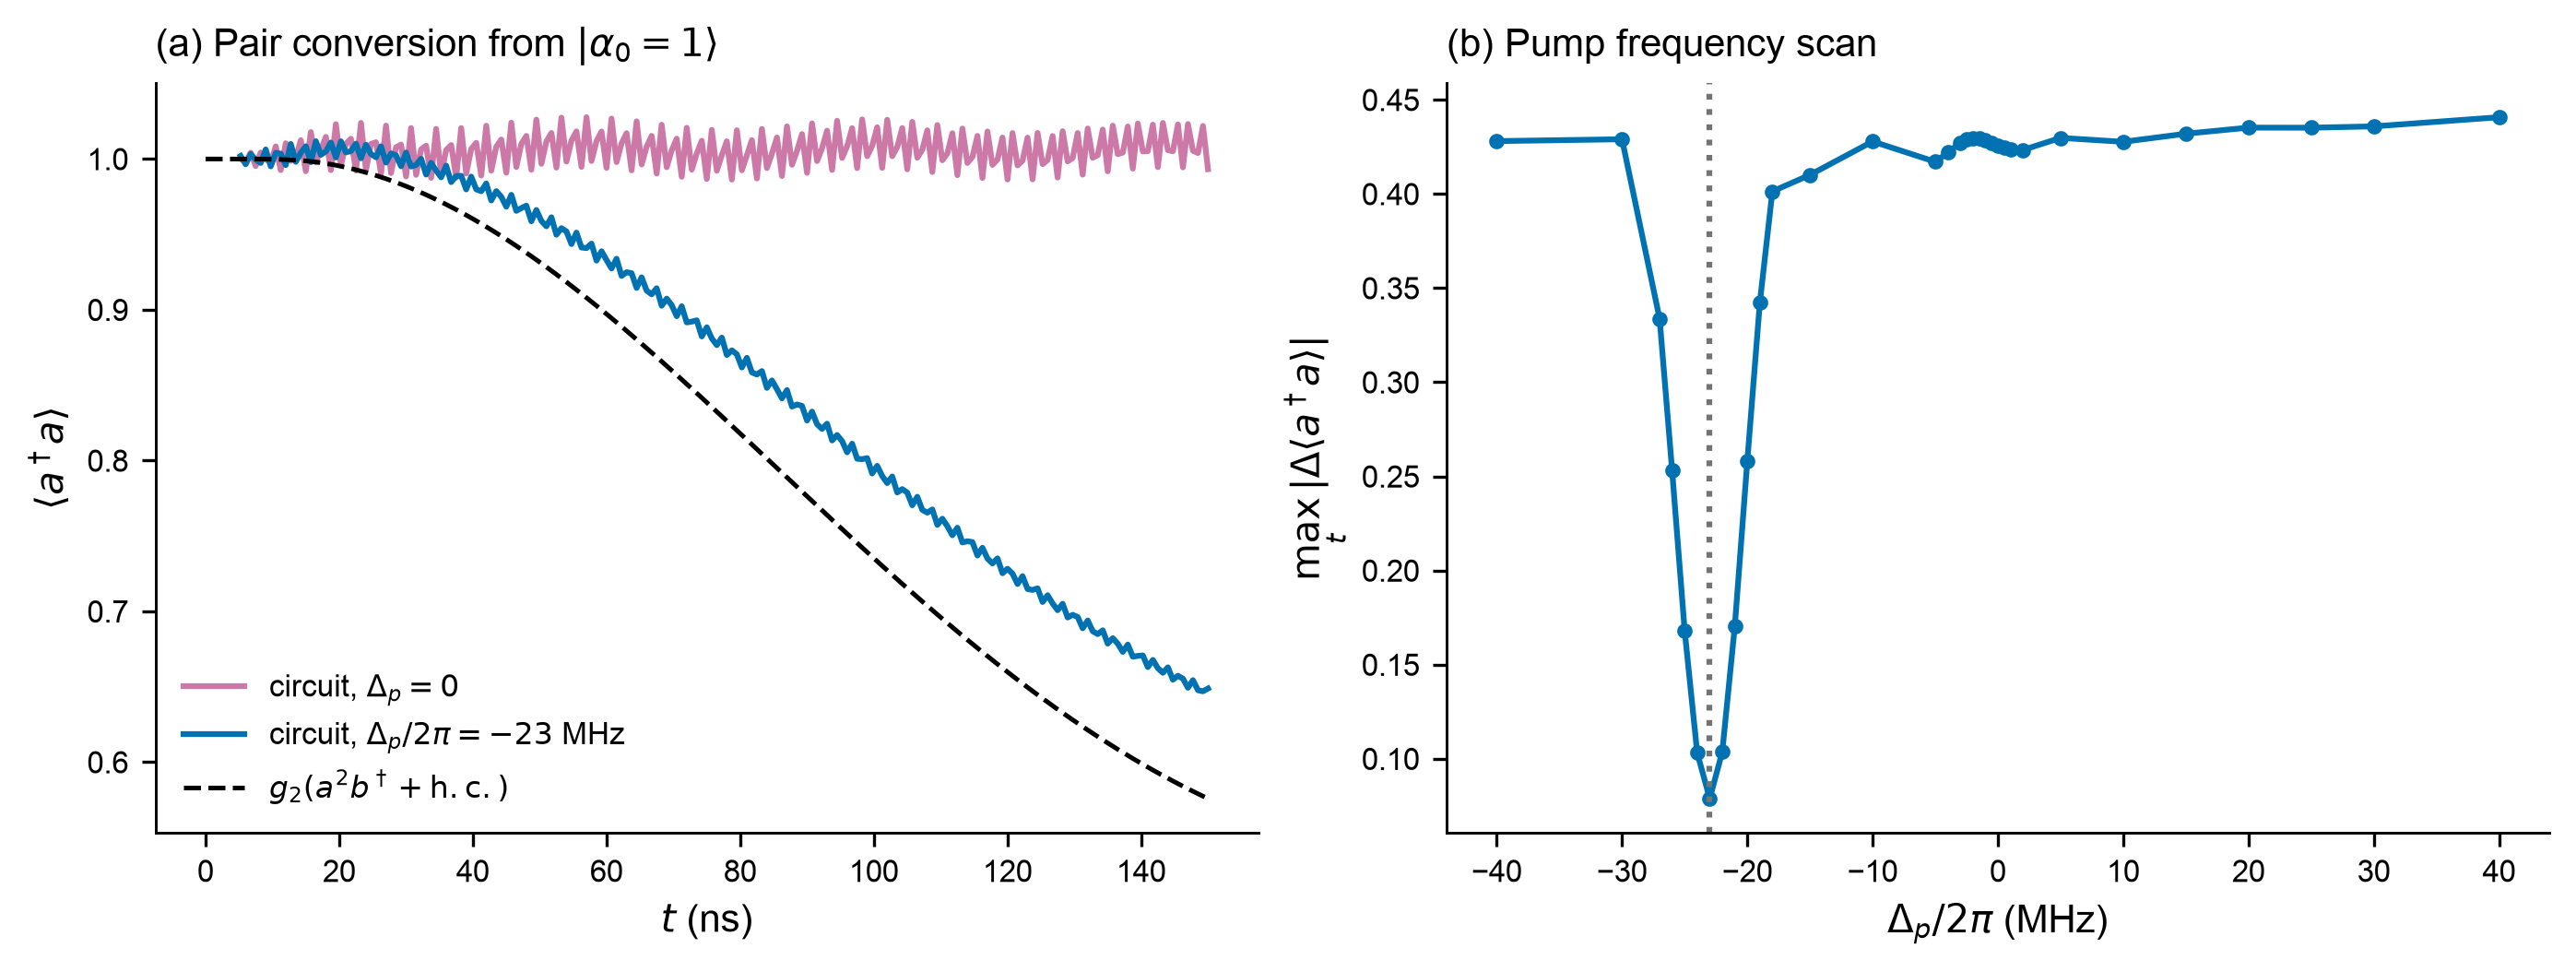

max |Δ⟨a†a⟩| vs the g2 model (5 ns average): 0.43 at the textbook pump, 0.07 with the pump moved by −23 MHz
Off-resonant buffer occupation estimate: n_b ≈ 0.070


In [3]:
with redirect_stdout(io.StringIO()):
    F.circuit_check()
show("s2/task_2_4_circuit")
d0, d23 = (F.load(f"circuit_na14_nb6_T0.15_dp{dp}.json")[0] for dp in (0, -23))
nb_pred = (EJ * eps_p * PB * exp(-Phi / 2) / (WB - WP))**2
print(f"max |Δ⟨a†a⟩| vs the g2 model (5 ns average): {d0['max_abs_diff_na_averaged']:.2f} at the textbook pump, "
      f"{d23['max_abs_diff_na_averaged']:.2f} with the pump moved by −23 MHz")
print(f"Off-resonant buffer occupation estimate: n_b ≈ {nb_pred:.3f}")


**Circuit calibration.** (a) Memory occupation under the nominal pump and a pump detuned by $\Delta_p/2\pi=-23$ MHz, compared with the cubic exchange model; circuit curves use a 6-ns display average. (b) Maximum occupation mismatch after a 5-ns average, scanned at $(N_a,N_b)=(10,4)$. Tests at $(12,5)$ and $(14,6)$ support the local minimum near $-23$ MHz. Retuning reduces the mismatch from about 0.43 to 0.07 photons but does not eliminate it. This shift belongs to the specified short, closed-system test, not to a calibrated device or the readout protocols below. [ATS pumping and calibration in experiment](https://arxiv.org/html/2307.06617v2#S4).


## (b) Contrast and bit-flip relaxation

For initial memory states $|\pm\alpha\rangle$, let $\beta_\pm(t)=\langle b(t)\rangle_\pm$. At weak drive,

$$C_b=|\mathrm{Re}(\bar\beta_+-\bar\beta_-)|\simeq\frac{|\epsilon_Z|}{\alpha g_2},$$

where bars average the finite-time plateau over 3.8–4 µs. We retain both loss channels with $g_2/2\pi=0.763$ MHz, $\kappa_b/2\pi=2.6$ MHz and $\kappa_a/2\pi=9.3$ kHz.

As in Task 2.1, $\Gamma_X$ is the decay rate of the logical population imbalance. Its relaxation time is $1/\Gamma_X$; a symmetric one-way switching rate is $\Gamma_X/2$. With a constant memory drive, ordinary memory-parity blocks no longer decouple. The stored spectral calculation uses the full Liouvillian, checked against resolvable time-domain decay at smaller cat sizes. A slow eigenvalue must couple to the measured imbalance to represent its relaxation.


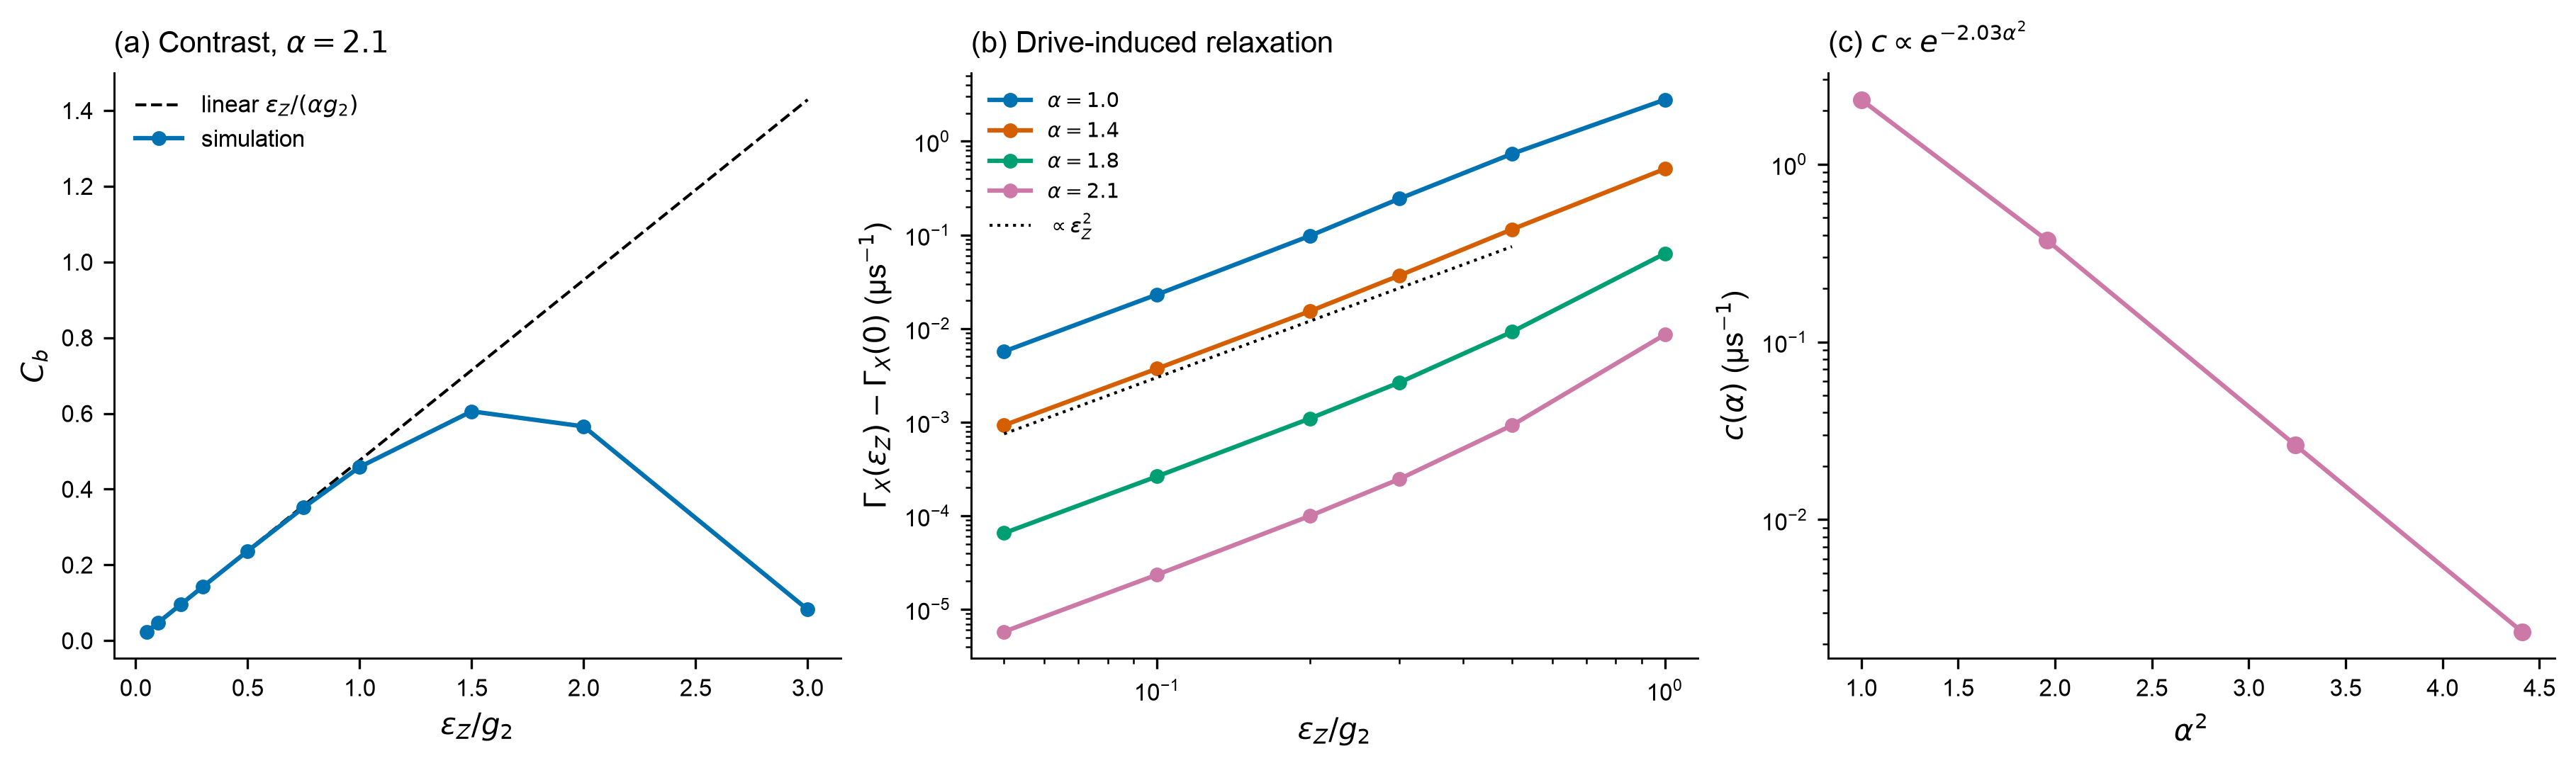

ε_Z/g₂,Γ_X (1/µs),1/Γ_X,C_b
0,3.85e-07,2.6 s,—
0.05,6.16e-06,162 ms,0.0238
0.1,2.38e-05,42 ms,0.0476
0.2,9.99e-05,10 ms,0.0951
0.3,0.000247,4.05 ms,0.1425
0.5,0.000924,1.08 ms,0.2368
1,0.00861,116 µs,0.4587


c(alpha) falls as exp(-2.03 alpha^2)


In [4]:
def gx_by_eps(alpha):
    rows = [d for d in F.load(f"gx_two_a{alpha:.2f}_*.json")
            if d["n_th"] == 0 and abs(d["kappa_a"] / (2 * pi) - 9.3e-3) < 1e-9 and abs(d["kappa_b"] / (2 * pi) - 2.6) < 1e-9]
    best = {}
    for d in rows:                                            # largest truncation per eps_Z
        k = d["eps_z_over_g2"]
        if k not in best or d["na"] * d["nb"] > best[k]["na"] * best[k]["nb"]:
            best[k] = d
    return {k: best[k]["gamma_x"] for k in sorted(best)}

ro = F.load("readout_a2.10_32x8_T4.json")[0]["runs"]
eps = np.array([r["eps_over_g2"] for r in ro])
bss = np.array([r["b_ss"][0] for r in ro]); blin = np.array([r["b_ss_linear"] for r in ro])
alphas = (1.0, 1.4, 1.8, 2.1)
gx = {a: gx_by_eps(a) for a in alphas}
c = np.array([(gx[a][0.1] - gx[a][0.0]) / 0.1**2 for a in alphas])   # Delta Gamma_X = c eps^2
slope = np.polyfit(np.array(alphas)**2, np.log(c), 1)[0]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
ax[0].plot(eps, -2*blin, "k--", lw=1, label=r"linear $\epsilon_Z/(\alpha g_2)$")
ax[0].plot(eps, -2*bss, "o-", color="C0", ms=4, label=r"simulation")
ax[0].set(xlabel=r"$\epsilon_Z/g_2$", ylabel=r"$C_b$"); ax[0].legend()
P.panel(ax[0], "a", r"Contrast, $\alpha=2.1$")
for i, a in enumerate(alphas):
    e = np.array([k for k in gx[a] if 0 < k <= 1]); g = np.array([gx[a][k] for k in e])
    ax[1].loglog(e, g - gx[a][0], "o-", color=f"C{i}", ms=4, label=rf"$\alpha={a}$")
ee = np.array([0.05, 0.5]); ax[1].loglog(ee, 0.3 * ee**2, "k:", lw=1, label=r"$\propto\epsilon_Z^2$")
ax[1].set(xlabel=r"$\epsilon_Z/g_2$", ylabel=r"$\Gamma_X(\epsilon_Z)-\Gamma_X(0)$ (µs$^{-1}$)"); ax[1].legend(fontsize=7)
P.panel(ax[1], "b", "Drive-induced relaxation")
ax[2].semilogy(np.array(alphas)**2, c, "o-", color="C3", ms=5)
ax[2].set(xlabel=r"$\alpha^2$", ylabel=r"$c(\alpha)$ (µs$^{-1}$)")
P.panel(ax[2], "c", rf"$c\propto e^{{-{-slope:.2f}\alpha^2}}$")
with redirect_stdout(io.StringIO()):
    P.save(fig, "s2/task_2_4_drive_sweep")
plt.close(fig); show("s2/task_2_4_drive_sweep", 1000)

g21 = gx[2.1]
def relaxation_time(g):
    us = 1 / g
    return f"{us / 1e6:.2g} s" if us >= 1e6 else f"{us / 1e3:.3g} ms" if us >= 1e3 else f"{us:.3g} µs"
snr_end = lambda r: r["snr"][-1] if isinstance(r["snr"], list) else r["snr"]
rows = []
for k in g21:
    if k > 1:
        continue
    i = list(eps).index(k) if k in eps else None
    rows.append({"ε_Z/g₂": f"{k:g}", "Γ_X (1/µs)": f"{g21[k]:.3g}", "1/Γ_X": relaxation_time(g21[k]),
                 "C_b": f"{-2*bss[i]:.4f}" if i is not None else "—"})
display(pd.DataFrame(rows).style.hide(axis="index"))
print(f"c(alpha) falls as exp(-{-slope:.2f} alpha^2)")


**Drive trade-off.** (a) Field separation at $\alpha=2.1$, from $(32,8)$ trajectories. (b) Added imbalance decay rate for four cat sizes, using the largest stored cutoff at each point and restricting the displayed rates to real slow modes through $\epsilon_Z/g_2=1$. (c) $c(\alpha)=[\Gamma_X(0.1g_2)-\Gamma_X(0)]/0.1^2$. The dashed guide in (a) is the weak-drive prediction; the dotted guide in (b) shows quadratic scaling.

Contrast remains within about 1% of its linear prediction through $\epsilon_Z=0.5g_2$, while $\Gamma_X$ rises from $3.85\times10^{-7}$ without drive to approximately $9.24\times10^{-4}$ µs⁻¹. At stronger drive the finite-time contrast eventually decreases. In the weak-drive range,

$$\Delta\Gamma_X\simeq c(\alpha)(\epsilon_Z/g_2)^2,\qquad c(\alpha)\propto e^{-2.03\alpha^2}$$

for the four sampled cat sizes. Both signal power and added relaxation therefore grow approximately quadratically with drive. Changing amplitude alone does not improve their ratio in this regime. The exponential cat-size dependence is consistent with drive-induced leakage followed by relaxation into the opposite logical state; it does not uniquely identify individual switching trajectories. [Second-order treatment of this mechanism](https://arxiv.org/html/2407.17299v2#A4).


## (c) Use the buffer response to improve the measurement

### Resonant modulation at fixed cat size

The linearized memory–buffer dynamics from Task 2.3 are underdamped. Neglecting the much smaller $\kappa_a$ in this estimate, their ringing frequency is

$$\omega_r=\sqrt{(2g_2\alpha)^2-\kappa_b^2/16},\qquad \omega_r/2\pi=3.14\ \mathrm{MHz}\quad(\alpha=2.1).$$

We compare a square drive, $\epsilon_Z(t)=\epsilon_{\max}$, with $\epsilon_{\max}\cos\omega_rt$ and $\epsilon_{\max}\mathrm{sgn}(\cos\omega_rt)$. The latter switches between the two drive signs. Pulses last **2 µs**; the buffer output is collected during the pulse and **2.5 µs of recovery**, giving a **4.5-µs observation window**.

We report two quantities directly supported by these runs:

$$\mathcal I=\kappa_b\int_0^{T_{\rm obs}}[\mathrm{Re}(\beta_+-\beta_-)]^2dt,
\qquad \delta_X=\frac{A_{\rm ref}-A_{\rm pulse}}{2A_{\rm ref}},$$

where $A=\mathrm{Re}\langle a(T_{\rm obs})\rangle_+$ for the positive initial codeword and the reference has no memory pulse. The exact symmetry $\beta_-=-\beta_+^*$ makes the field difference real. $\mathcal I$ measures the separation of conditional mean output fields; the archived key is `snr`. $\delta_X$ is recovered **amplitude loss relative to idle**. It approximates excess wrong-state population only when each logical branch has recovered the same amplitude. It is not a direct logical-projector measurement.

For coherent output with white Gaussian noise, $\mathcal I$ can be converted to a detector-dependent assignment estimate. These simulations do not sample measurement records, so the pulse comparison below uses $\mathcal I$ and $\delta_X$ rather than claiming single-shot fidelity.


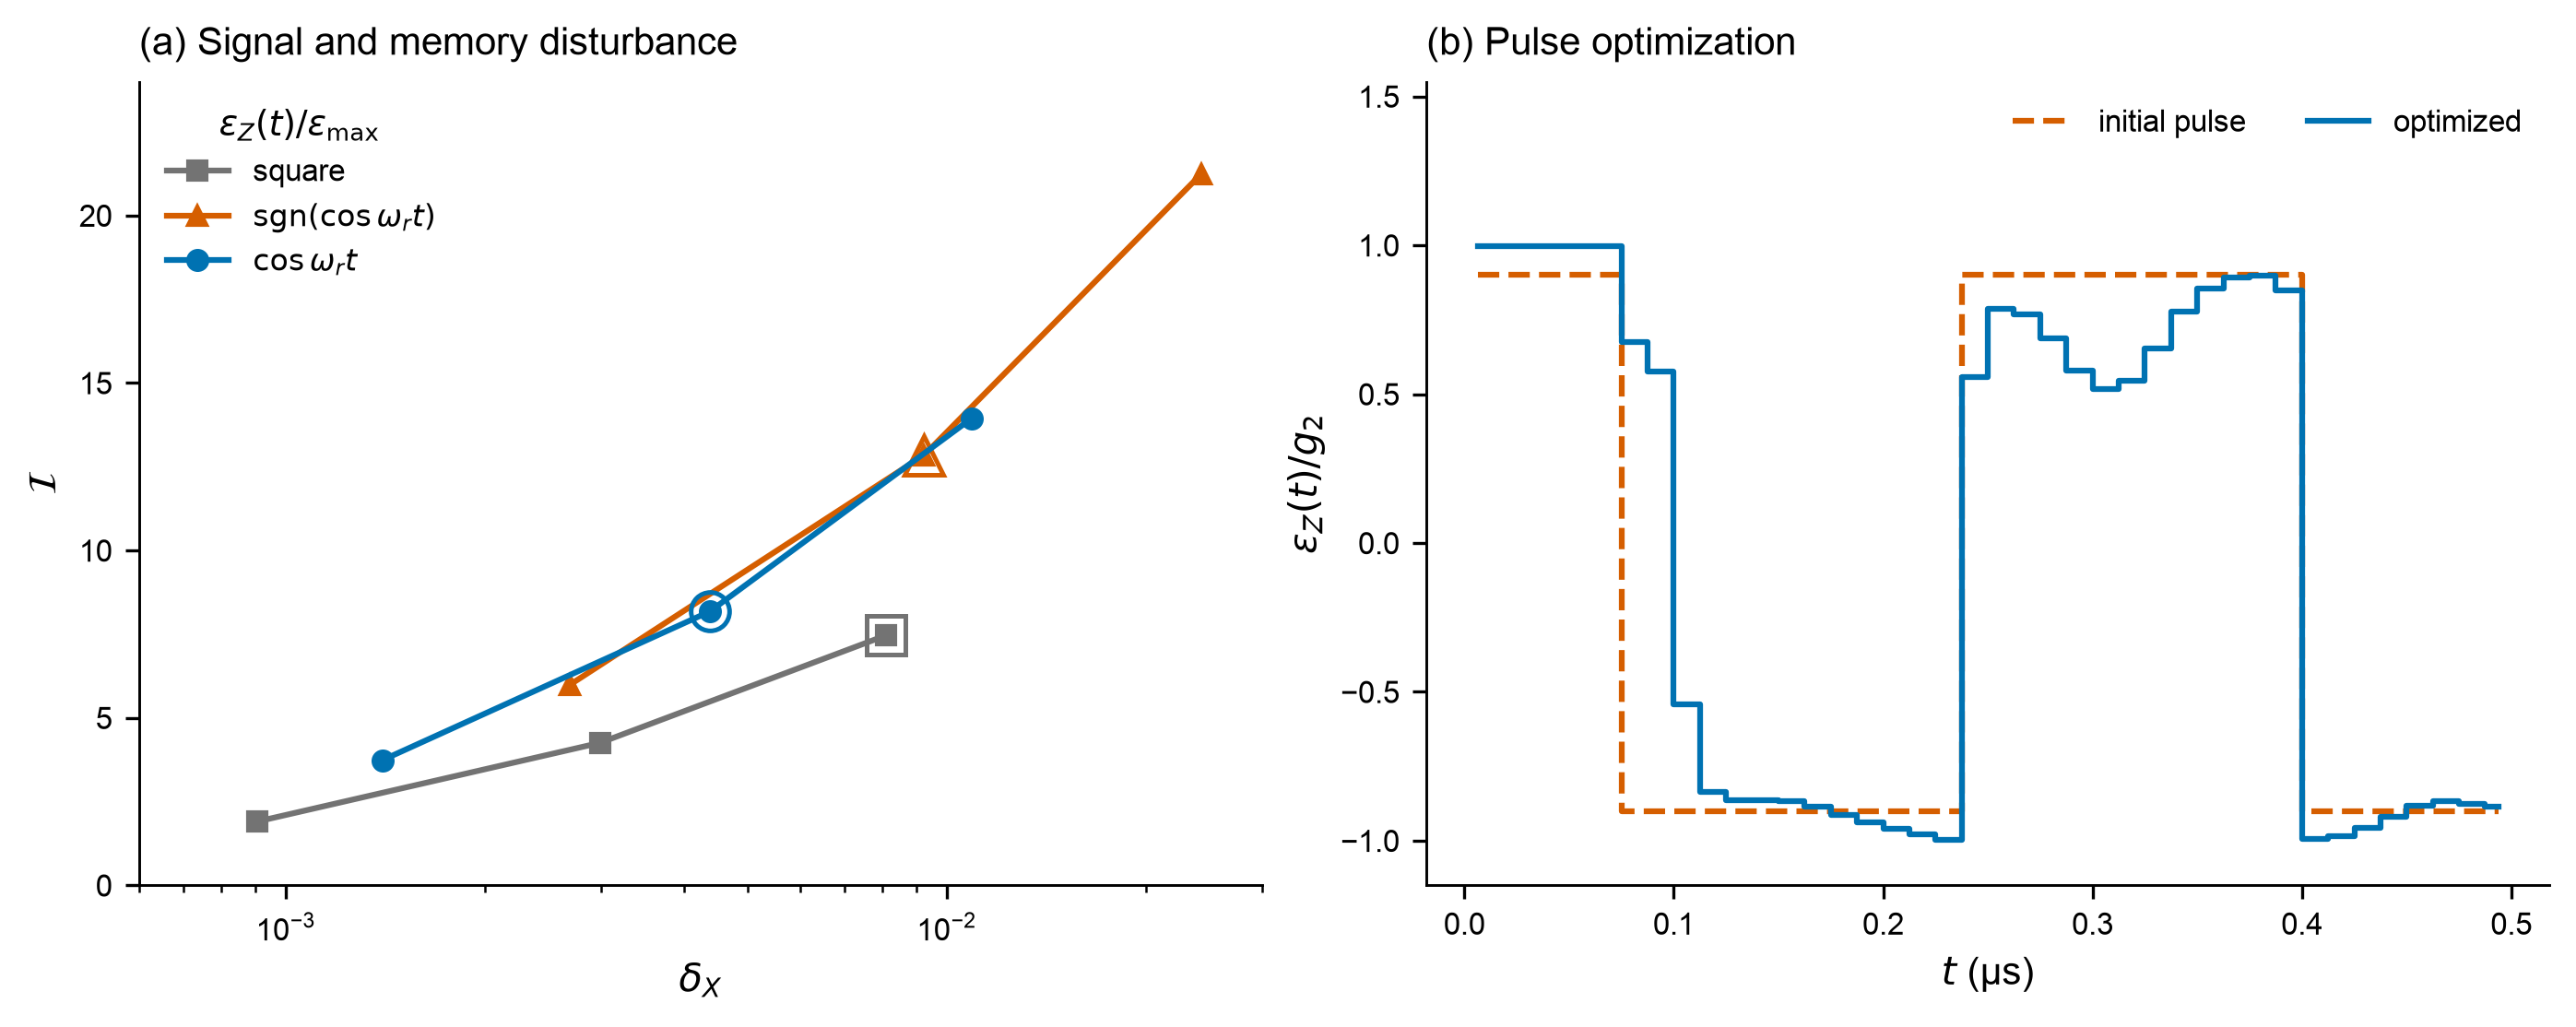

pulse,peak / g₂,I,δ_X,I/δ_X relative to square
square,1.000000,7.469,0.008104,1.00
resonant cosine,0.750000,8.178,0.004381,2.03
alternating sign,0.750000,12.844,0.009242,1.51


In [5]:
with redirect_stdout(io.StringIO()):
    F.better_readout()
show("s2/task_2_4_better_readout")
ps = F.load("pulse_a2.10_30x8_T2_peak.json")[0]
selected = [("square", 1.0), ("res", 0.75), ("bang", 0.75)]
names = {"square": "square", "res": "resonant cosine", "bang": "alternating sign"}
chosen = [next(r for r in ps["rows"] if r["family"] == f and r["level"] == peak) for f, peak in selected]
display(pd.DataFrame([{
    "pulse": names[r["family"]], "peak / g₂": r["level"], "I": f"{r['snr']:.3f}",
    "δ_X": f"{r['p_flip']:.4g}", "I/δ_X relative to square": f"{(r['snr']/r['p_flip'])/(chosen[0]['snr']/chosen[0]['p_flip']):.2f}",
} for r in chosen]).style.hide(axis="index"))


**Pulse comparison.** (a) Information versus recovered amplitude loss for peak drives $0.5$, $0.75$ and $1.0g_2$ at $(30,8)$; lines connect tested amplitudes. Open markers identify the table's examples. The cosine at $0.75g_2$ gives **9.5% more information and 45.9% less amplitude loss** than the square pulse at $1.0g_2$. This compares two driven protocols; the undriven-storage criterion is tested below. (b) A separate 0.5-µs optimization at $(30,8)$, with 2 µs recovery, showing the initial alternating-sign pulse (90% of the peak bound) and its optimized form.

A matched cutoff check is available for **0.5-µs** pulses, with the same 2.5-µs recovery. At equal peak $g_2$, the $(36,10)$ cosine gives **26.7% more information and 18.1% less amplitude loss** than the square. The table below compares $(32,8)$ and $(36,10)$. These shorter-pulse checks support the mechanism; they do not establish cutoff convergence of the 2-µs examples.


In [6]:
small = F.load("pulse_a2.10_32x8_T0.5_peak.json")[0]
large = F.load("pulse_a2.10_36x10_T0.5_peak.json")[0]
rows = []
for family in ("square", "res"):
    a = next(r for r in small["rows"] if r["family"] == family and r["level"] == 1)
    b = next(r for r in large["rows"] if r["family"] == family and r["level"] == 1)
    rows.append({"pulse": names[family], "I at 36×10": f"{b['snr']:.6f}", "δ_X at 36×10": f"{b['p_flip']:.6g}",
                 "relative change in I": f"{abs(a['snr']/b['snr']-1):.2%}",
                 "relative change in δ_X": f"{abs(a['p_flip']/b['p_flip']-1):.2%}"})
display(pd.DataFrame(rows).style.hide(axis="index"))


pulse,I at 36×10,δ_X at 36×10,relative change in I,relative change in δ_X
square,2.111474,0.0017215,0.00%,0.71%
resonant cosine,2.674335,0.00141017,0.00%,0.46%


### Preserve the storage rate by temporarily enlarging the cat

The fixed-size sweep motivates a stricter objective: keep the readout-stage $\Gamma_X$ below undriven storage at $\alpha=2.1$, $3.847\times10^{-7}$ µs⁻¹. Increasing $\alpha$ suppresses switching exponentially while reducing weak-drive field response only as $1/\alpha$. We test $\alpha:2.1\to2.6$ with a stronger readout $\epsilon_Z=0.1g_2$, then restore the original storage basis.

The sequence is **2 µs enlargement → 41.40 µs readout → 2 µs return → 2 µs recovery**. The buffer drive sets $\epsilon_d(t)=g_2\alpha(t)^2$, with ramps $s(u)=10u^3-15u^4+6u^5$, $0\le u\le1$. Signal is counted only through the end of the readout drive. Both this cycle and the fixed-size weak reference ($\epsilon_Z=0.05g_2$) target $\mathcal I=1$; all control and recovery time counts in the cycle duration. The weak reference reads for 108.22 µs and recovers for 2 µs, without ramps.

Here the final error **is measured with logical projectors**. For normalized even and odd cats $|C_\pm\rangle$ at storage amplitude 2.1, define orthonormal logical states $|0_L\rangle=(|C_+\rangle+|C_-\rangle)/\sqrt2$ and $|1_L\rangle=(|C_+\rangle-|C_-\rangle)/\sqrt2$. $p_X$ is population in the opposite state after recovery, without postselection; leakage is population outside their span.


protocol,cycle (µs),I,Γ_X (µs⁻¹),p_X,leakage
weak reference,110.22,1.000000,6.105e-06,0.0003306,8.11e-06
"enlarge, read, restore",47.40,0.999992,2.035e-07,7.948e-06,8.11e-06


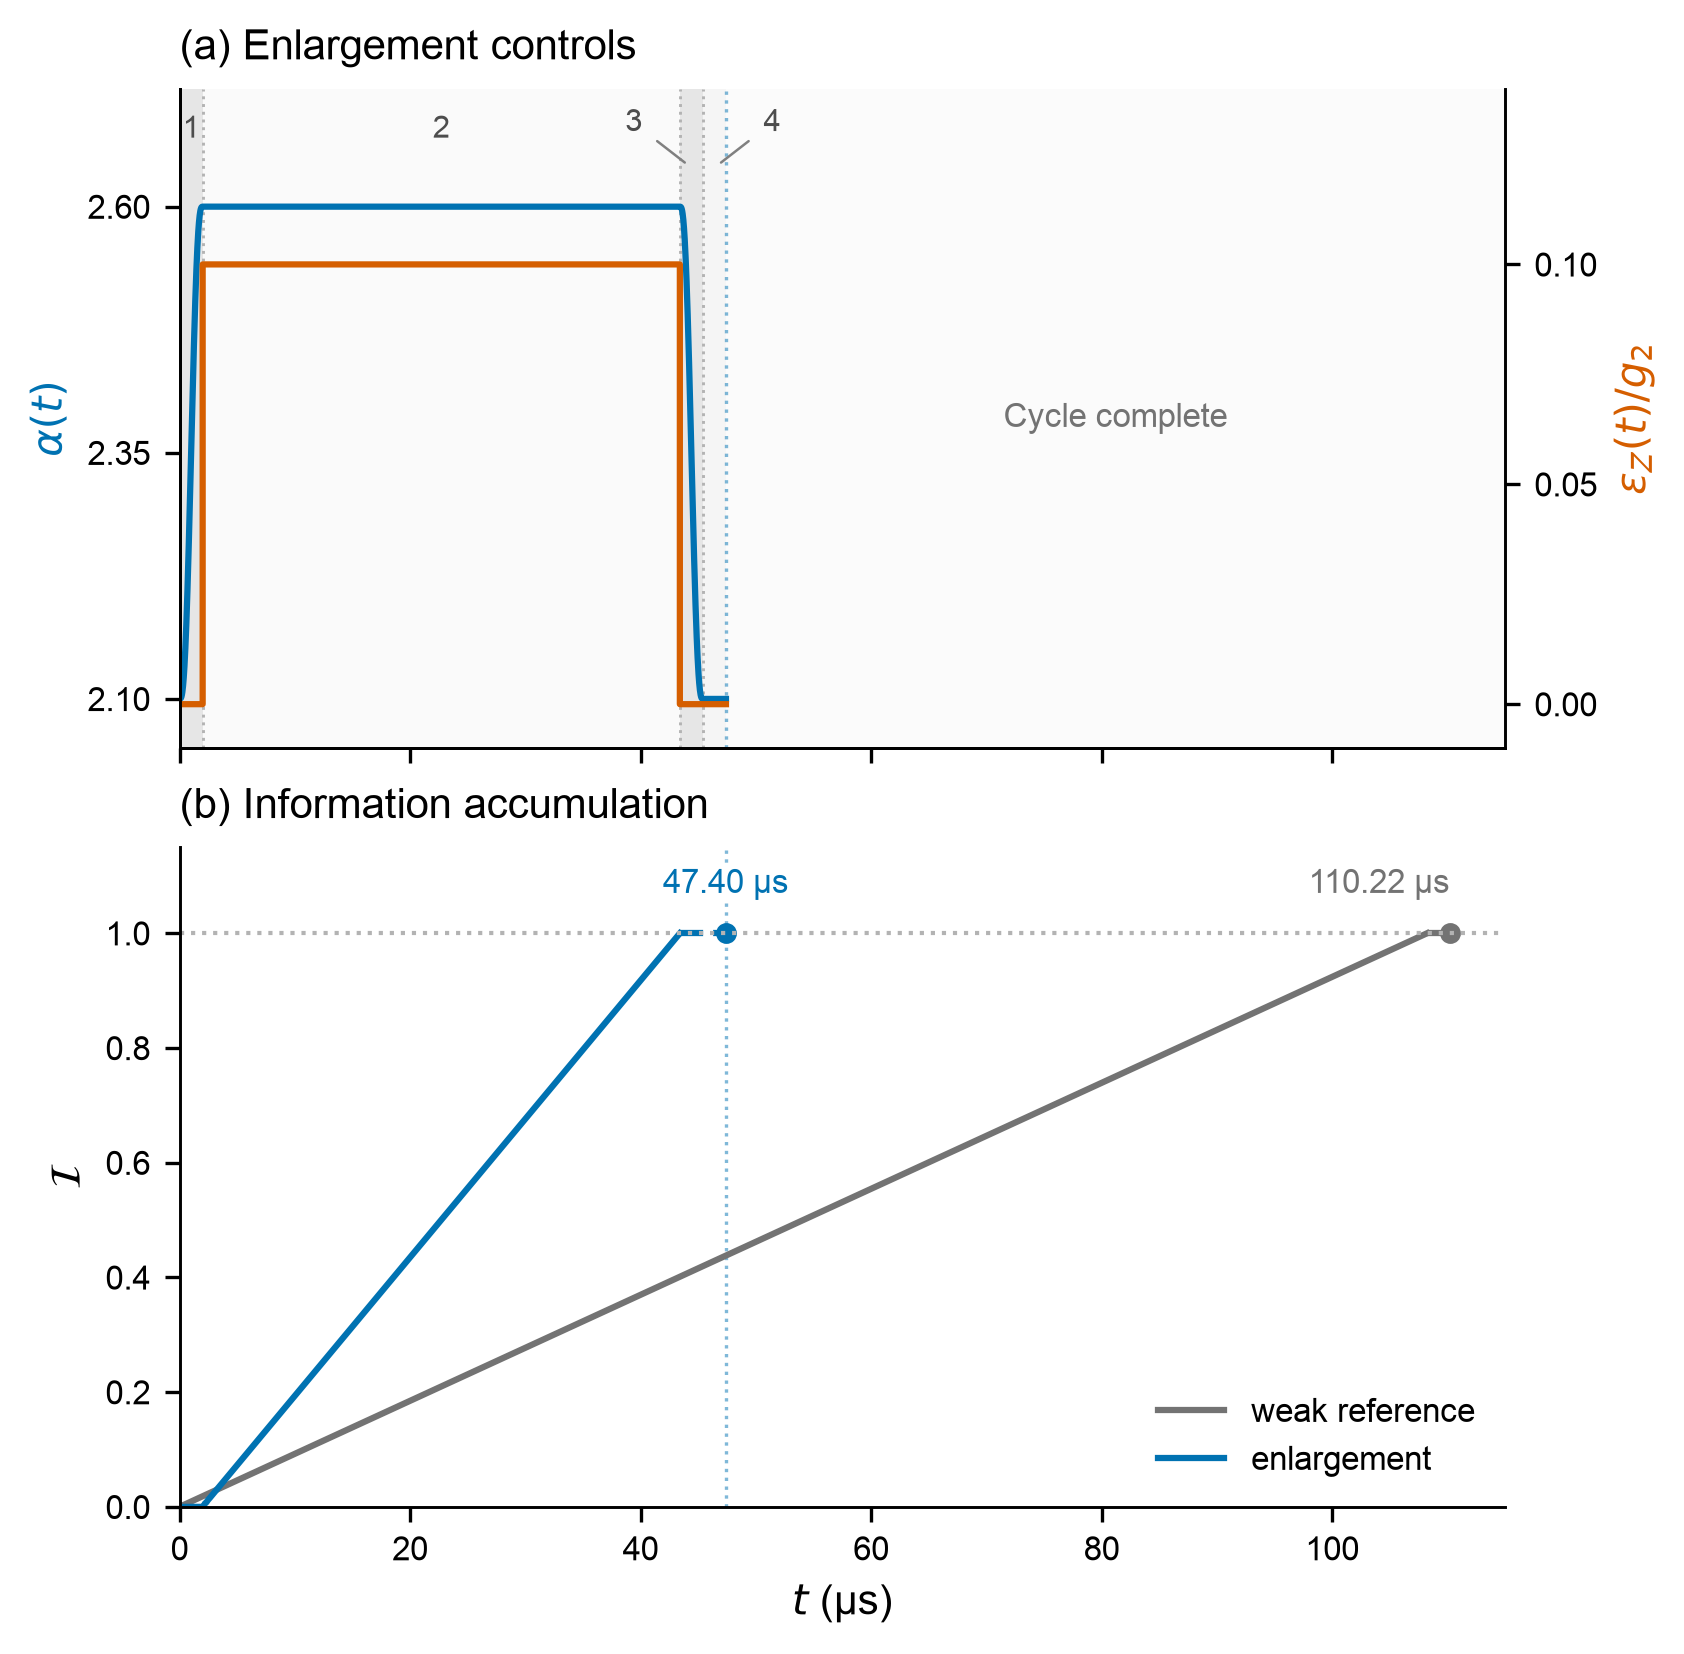

In [7]:
enlargement = json.loads((ROOT / "results/task_2_4_enlargement.json").read_text())
# The compact archive retains source hashes, convergence records and the selected raw trajectories.
cycles = {key: value["metrics"] for key, value in enlargement["cycles"].items()}
plateau_rates = {"baseline": enlargement["weak_readout_reference"]["gamma_x_per_us"],
                 "amplified": enlargement["spectral_validation"]["primary_result"]["gamma_x_per_us"]}
display(pd.DataFrame([{
    "protocol": label, "cycle (µs)": f"{cycles[key]['cycle_duration_us']:.2f}",
    "I": f"{cycles[key]['mean_field_information_at_read_end']:.6f}",
    "Γ_X (µs⁻¹)": f"{plateau_rates[key]:.4g}",
    "p_X": f"{cycles[key]['max_wrong_logical_population']:.4g}",
    "leakage": f"{max(cycles[key]['final_leakage']):.3g}",
} for key, label in [("baseline", "weak reference"), ("amplified", "enlarge, read, restore")]]).style.hide(axis="index"))


from scipy.integrate import cumulative_trapezoid
archive = np.load(ROOT / "results/task_2_4_enlargement_trajectories.npz", allow_pickle=False)
fig, (ax_alpha, ax_info) = plt.subplots(2, 1, sharex=True, figsize=(5.5, 5.4), layout="constrained")
ax_drive = ax_alpha.twinx()
for key, label, color in [("baseline", "weak reference", "0.45"), ("amplified", "enlargement", "C0")]:
    t = archive[f"{key}_t"]
    e = archive[f"{key}_expects"]
    info = cumulative_trapezoid(enlargement["configuration"]["kappa_b"] * (e[1,1].real-e[0,1].real)**2, t, initial=0)
    end = cycles[key]["read_end_us"]
    j = np.flatnonzero(np.isclose(t, end, rtol=0, atol=1e-10))[0]
    assert np.isclose(info[j], cycles[key]["mean_field_information_at_read_end"], rtol=1e-10)
    wrong = max(e[0,6,-1].real, e[1,7,-1].real)
    assert np.isclose(wrong, cycles[key]["max_wrong_logical_population"], rtol=1e-10)
    assert np.max(np.abs(e[:,6]+e[:,7]+e[:,8]-e[:,9])) < 1e-10
    ax_info.plot(t[:j+1], info[:j+1], color=color, label=label)
    ax_info.plot([end, t[-1]], [info[j], info[j]], color=color, ls="--")
    ax_info.plot(t[-1], info[j], "o", color=color, ms=4)
    ax_info.annotate(f"{t[-1]:.2f} µs", (t[-1],info[j]), xytext=(0,8),
                     textcoords="offset points", ha="right" if key=="baseline" else "center",
                     va="bottom", color=color, fontsize=8,
                     bbox={"facecolor":"white", "edgecolor":"none", "pad":.5})
ax_info.axhline(1, color="0.7", ls=":", lw=1)
ax_info.set(xlabel=r"$t$ (µs)", ylabel=r"$\mathcal{I}$", xlim=(0,115), ylim=(0,1.15))
ax_info.legend(loc="lower right")
P.panel(ax_info, "b", "Information accumulation")
params = enlargement["cycles"]["amplified"]["parameters"]
t = archive["amplified_t"]; ramp=params["ramp"]; read=params["read_time"]
smooth = lambda u: 10*u**3-15*u**4+6*u**5
u = np.clip(t/ramp, 0, 1); v=np.clip((t-ramp-read)/ramp,0,1)
al = 2.1 + (params["alpha_readout"]-2.1)*(smooth(u)-smooth(v))
drive=np.where((t>=ramp)&(t<ramp+read),params["ratio"],0)
ax_alpha.plot(t, al, color="C0")
ax_alpha.set(ylabel=r"$\alpha(t)$", ylim=(2.05,2.72), yticks=[2.1,2.35,2.6])
ax_drive.step(t, drive, where="post", color="C1")
ax_drive.set(ylabel=r"$\epsilon_Z(t)/g_2$", ylim=(-.01,.14), yticks=[0,.05,.1])
ax_alpha.yaxis.label.set_color("C0")
ax_drive.yaxis.label.set_color("C1")
ax_drive.spines["right"].set_visible(True)
# True-duration stage bands and compact indices keep the brief ramps visible.
stage_edges = [0, ramp, ramp+read, 2*ramp+read, t[-1]]
for index, left, right, shade in zip(("1", "2", "3", "4"), stage_edges[:-1],
                                    stage_edges[1:], ("0.90", "0.98", "0.90", "0.96")):
    ax_alpha.axvspan(left, right, facecolor=shade, edgecolor="none", zorder=0)
    center = (left+right)/2
    if index in ("3", "4"):
        label_x = center + (-5 if index=="3" else 5)
        ax_alpha.annotate(index, (center,.88), xycoords=ax_alpha.get_xaxis_transform(),
                          xytext=(label_x,.97), textcoords=ax_alpha.get_xaxis_transform(),
                          ha="center", va="top", fontsize=7.5, color="0.3",
                          arrowprops={"arrowstyle":"-", "color":"0.5", "lw":.6})
    else:
        ax_alpha.text(center, .96, index, transform=ax_alpha.get_xaxis_transform(),
                      ha="center", va="top", fontsize=7.5, color="0.3")
for boundary in stage_edges[1:-1]:
    ax_alpha.axvline(boundary, color="0.7", ls=":", lw=.7, zorder=1)
cycle_end = cycles["amplified"]["cycle_duration_us"]
ax_alpha.axvspan(cycle_end, 115, facecolor="0.985", edgecolor="none", zorder=0)
ax_alpha.text((cycle_end+115)/2, .5, "Cycle complete", transform=ax_alpha.get_xaxis_transform(),
              ha="center", va="center", color="0.45", fontsize=8)
for axis in (ax_alpha, ax_info):
    axis.axvline(cycle_end, color="C0", ls=":", lw=.8, alpha=.5, zorder=0)
ax_info.set_xlim(0,115)
P.panel(ax_alpha, "a", "Enlargement controls")
fig.canvas.draw()
assert np.allclose([ax_alpha.get_position().x0, ax_alpha.get_position().x1],
                   [ax_info.get_position().x0, ax_info.get_position().x1])
with redirect_stdout(io.StringIO()):
    P.save(fig, "s2/task_2_4_enlargement")
plt.close(fig)
show("s2/task_2_4_enlargement", 560)


**Enlargement cycle.** Both panels use the same elapsed-time axis, with $t=0$ at the protocol start. (a) Target cat amplitude (blue, left axis) and readout drive (orange, right axis). Shaded stages 1–4 show enlargement (2 µs), readout (41.40 µs), return (2 µs) and recovery (2 µs); dotted vertical lines mark the transitions. Controls are shown only through the 47.40-µs cycle; the later interval is marked complete. (b) Counted information reconstructed from the complex buffer fields, with enlargement in blue and the weak reference in gray. Solid curves end when the readout drive stops; dashed segments include return/recovery without counting further emission, and labeled dots mark complete-cycle endpoints (47.40 µs and 110.22 µs). The blue dotted guide aligns the enlargement endpoint across both panels. The axis extends to 115 µs only to leave space around the longer reference. Final populations use $(32,12)$ for the weak reference and $(38,16)$ for enlargement; their plateau rates use $(32,12)$ and $(40,16)$.


The complete enlargement cycle is **47.40 µs**, compared with **110.22 µs** for the weak reference: **2.33 times faster** at the same calculated signal. Its recovered wrong-state population is $7.95\times10^{-6}$ versus $3.31\times10^{-4}$.

The separately estimated readout-stage rate is $\Gamma_X=2.035\times10^{-7}$ µs⁻¹, below undriven storage's $3.847\times10^{-7}$ µs⁻¹. An earlier joint rate-cutoff increase changes the estimate by 2.12%; the last separate memory and buffer increases change it by 0.70% and 0.53%; the final cycle cutoff increase changes $p_X$ by 0.78%. These are empirical comparisons, not rigorous error bars. This evidence meets a stricter protection criterion than the fixed-size pulse comparison. The two strategies use different signal targets and observation windows and are not ranked by their quoted durations.


## (d) Why these controls help

**Resonant response.** In the linearized model, sampling the pulse gives a vector $\epsilon$ and a causal response matrix $K$ with $\Delta b=K\epsilon$. At fixed pulse energy, maximizing $\lVert K\epsilon\rVert^2/\lVert\epsilon\rVert^2$ selects the leading right singular vector of $K$. This is the optimum for the linear signal objective, not for logical error. Its spectrum peaks near the memory–buffer ringing frequency.


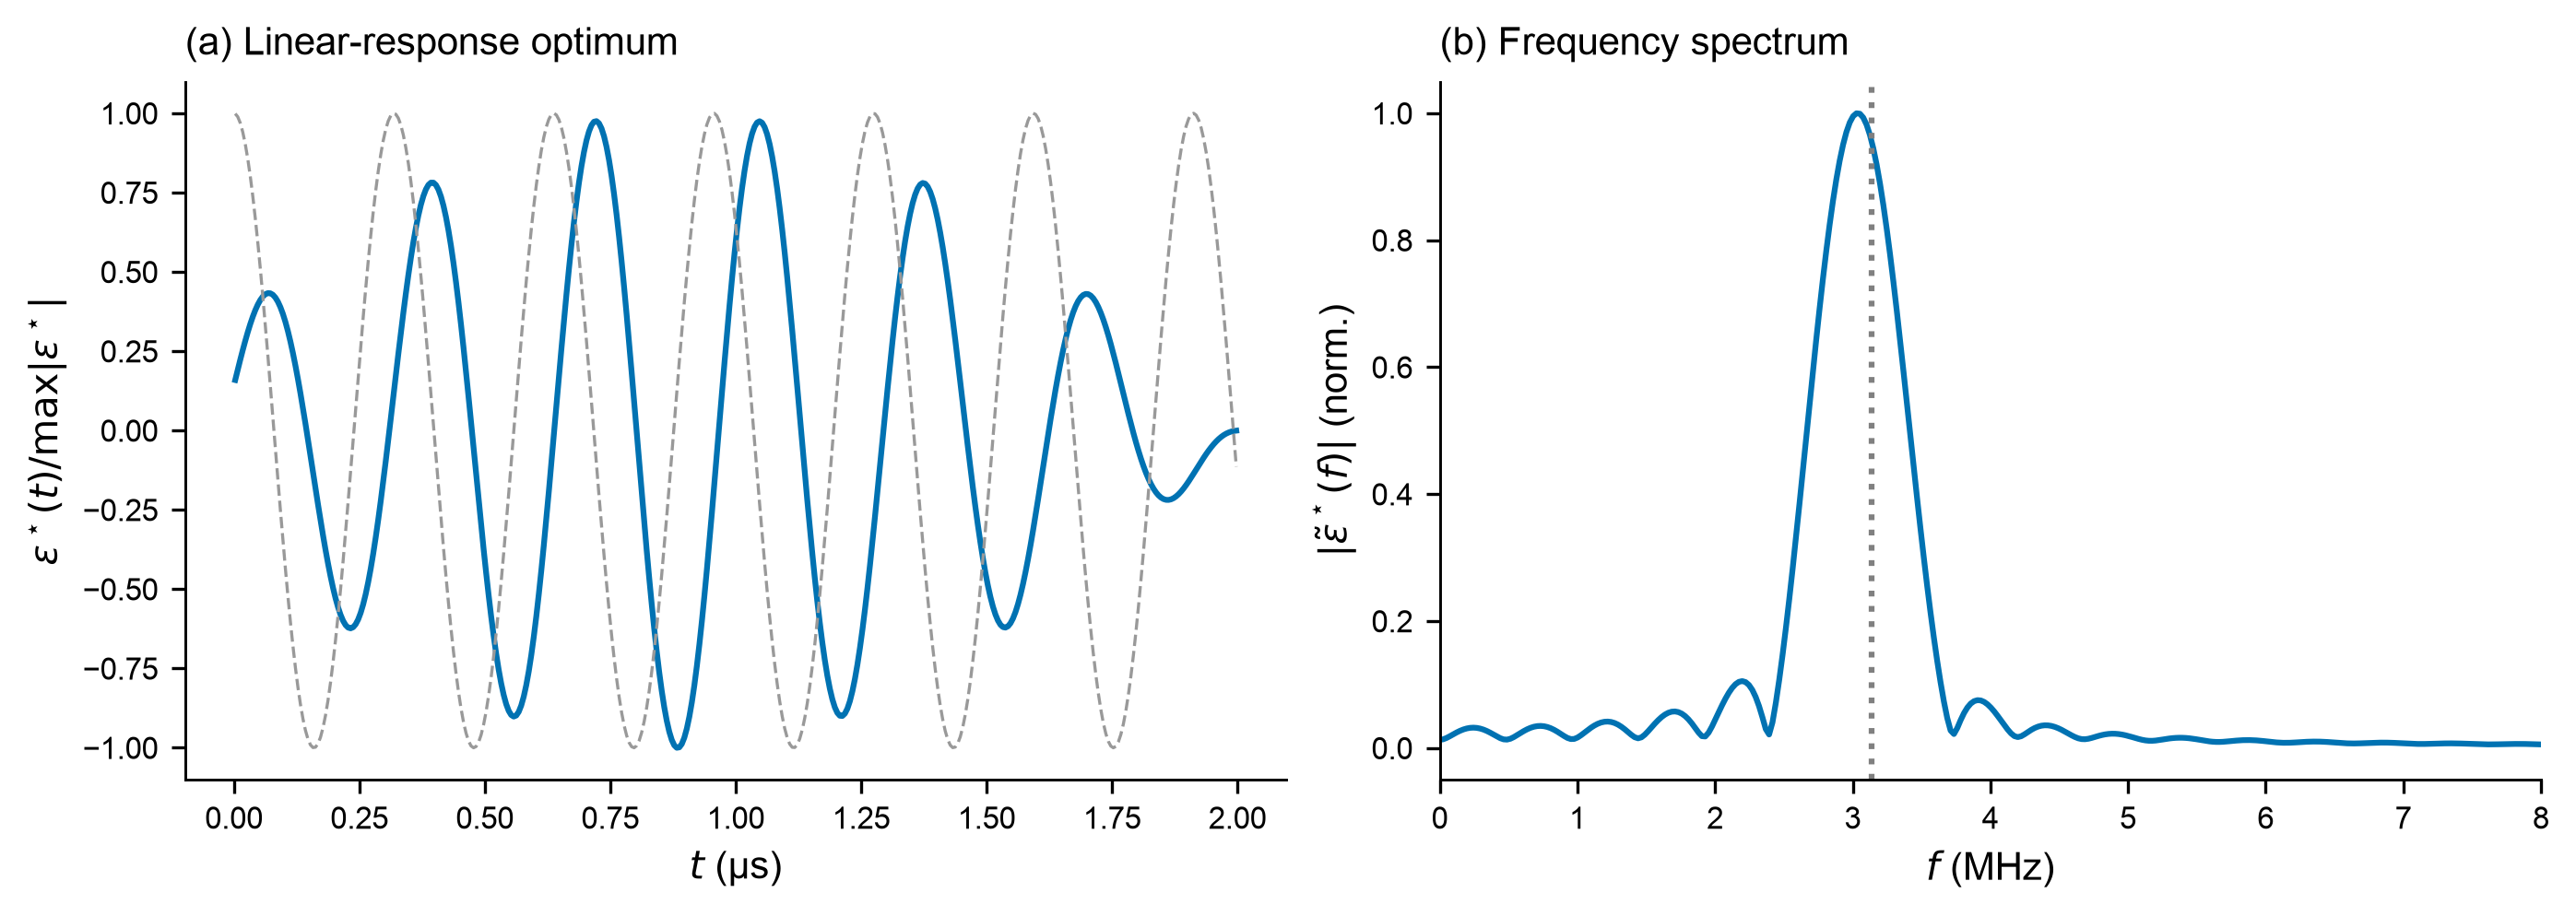

SVD pulse peaks at 3.03 MHz; ringing frequency ω_r/2π = 3.14 MHz


In [8]:
T, n = 2.0, 400
e_svd, _, dt = linresp.optimal_pulse(2.1, T, n, 1.0)
t = (np.arange(n) + 0.5) * dt
wr = np.sqrt(4 * G2**2 * 2.1**2 - KAPPA_B**2 / 16)
f = np.fft.rfftfreq(8192, dt); spec = np.abs(np.fft.rfft(e_svd, 8192))

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2), layout="constrained")
ax[0].plot(t, e_svd / np.abs(e_svd).max(), color="C0", label=r"SVD-optimal $\epsilon^\star(t)$")
ax[0].plot(t, np.cos(wr * t), color="0.6", lw=0.8, ls="--", label=r"$\cos\omega_r t$")
ax[0].set(xlabel=r"$t$ (µs)", ylabel=r"$\epsilon^\star(t)/\max|\epsilon^\star|$"); 
P.panel(ax[0], "a", r"Linear-response optimum")
ax[1].plot(f, spec / spec.max(), color="C0"); ax[1].axvline(wr / (2 * pi), color="0.5", ls=":")
ax[1].set(xlabel=r"$f$ (MHz)", ylabel=r"$|\tilde\epsilon^\star(f)|$ (norm.)", xlim=(0, 8))
P.panel(ax[1], "b", "Frequency spectrum")
with redirect_stdout(io.StringIO()):
    P.save(fig, "s2/task_2_4_svd_pulse")
plt.close(fig); show("s2/task_2_4_svd_pulse", 860)
print(f"SVD pulse peaks at {f[spec.argmax()]:.2f} MHz; ringing frequency ω_r/2π = {wr / (2 * pi):.2f} MHz")


**Linear optimum.** (a) Leading singular-vector pulse (blue) for a 2-µs window, with a resonant cosine (gray dashes) for comparison. (b) Normalized Fourier magnitude; the dotted line marks $\omega_r/2\pi$. The finite window limits frequency resolution. The calculation uses the two-mode linear response, not adiabatic buffer elimination.

**Nonlinear optimization.** The full-model optimizer varies 40 pulse bins under a peak-amplitude bound and maximizes $J=\mathcal I-\mu\delta_X$, with $\mu$ equal to the square pulse's $\mathcal I/\delta_X$. It starts from an alternating-sign resonant pulse. In nine completed settings it achieves 1.26–1.71 times the square pulse's signal per amplitude loss, but only 0.98–1.16 times its own start. This supports resonant shaping locally; initialization prevents interpreting it as an independent discovery or global optimum.


In [9]:
opt = sorted((d for d in F.load("opt_*.json") if not d.get("partial") and d["nb"] >= 8),
             key=lambda d: (d["alpha"], d["T"], d["peak"]))
spf = lambda x: x["snr"] / x["p_flip"]
display(pd.DataFrame([{
    "α": d["alpha"], "pulse duration (µs)": d["T"], "peak / g₂": d["peak"],
    "I/δ_X vs square": f"{spf(d['best']) / spf(d['square']):.2f}",
    "I/δ_X vs initial pulse": f"{spf(d['best']) / spf(d['history'][0]):.2f}",
} for d in opt]).style.hide(axis="index").format({"α": "{:g}", "pulse duration (µs)": "{:g}", "peak / g₂": "{:g}"}))


α,pulse duration (µs),peak / g₂,I/δ_X vs square,I/δ_X vs initial pulse
1.4,0.5,0.5,1.55,1.02
1.4,0.5,1,1.66,1.02
1.4,1,0.5,1.59,1.02
1.8,0.5,0.5,1.36,1.03
1.8,0.5,1,1.71,1.14
1.8,1,0.5,1.32,0.98
2.1,0.5,0.5,1.26,1.05
2.1,0.5,1,1.56,1.16
2.1,1,0.5,1.30,1.11


**Enlargement.** Doubling the readout drive while changing $\alpha$ from 2.1 to 2.6 predicts a field gain $2(2.1/2.6)=1.615$. The simulated gain is 1.616, giving 2.61 times the plateau information rate. The complete-cycle speedup falls to 2.33 after the ramps and recovery, while the increased cat separation suppresses switching. The population calculation tests that this benefit survives return to storage.

**Scope.** The pulse and enlargement results establish improvements within the cubic two-mode model. The short exact-sine circuit test does not validate their rare switching rates or complete cycles with circuit corrections. Conditional mean information does not establish single-shot assignment fidelity. For unit-efficiency homodyne detection of coherent Gaussian output, $\mathcal I=1$ corresponds to a 15.9% assignment-error estimate; it is only a comparison target here. The selected [enlargement evidence](../results/task_2_4_enlargement.json) records the original simulation source, solver checks and cutoff comparisons. Main's pulse simulations are generated by `research/s2/pulse_eval.py`, its static rates by `gx_eig.py`, and its optimizer by `pulse_opt.py`.

The circuit calibration follows the setting studied by [Réglade et al.](https://arxiv.org/html/2307.06617v2); the leakage mechanism is informed by [Dubovitskii](https://arxiv.org/html/2407.17299v2). The role of the buffer in control-induced logical information is also developed by [Gautier, Mirrahimi and Sarlette](https://arxiv.org/abs/2303.00760). The quantitative protocol comparisons here come from this repository's simulations.
